<a href="https://colab.research.google.com/github/adishetty112/pneumonia-detection-deep-learning/blob/main/pneumonia_detection_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection from Chest X-rays (Custom CNN vs Transfer Learning)
Dataset: [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)

**Before running:** Runtime → Change runtime type → **T4 GPU**.
You also need your `kaggle.json` (Kaggle → Settings → API → *Create New Token*).

## 1. Download dataset from Kaggle

In [ ]:
!pip install -q kaggle
from google.colab import files
print("Upload your kaggle.json file:")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip -q -o chest-xray-pneumonia.zip -d /content/data
!ls /content/data/chest_xray

Upload your kaggle.json file:


Saving kaggle .json to kaggle .json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [02:10<00:00, 18.9MB/s]

chest_xray  __MACOSX  test  train  val


## 2. Imports & config

In [ ]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH = 32
DATA_DIR = "/content/data/chest_xray"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR  = os.path.join(DATA_DIR, "test")

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load data
The original `val` folder has only 16 images (unreliable), so we create a proper **80/20 train/validation split** from the training folder. The `test` folder is kept untouched for final evaluation.

In [ ]:
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")

val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG_SIZE, batch_size=BATCH, label_mode="binary")

test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="binary", shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)   # ['NORMAL', 'PNEUMONIA'] -> 0, 1

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


## 4. Explore data (samples + class imbalance)

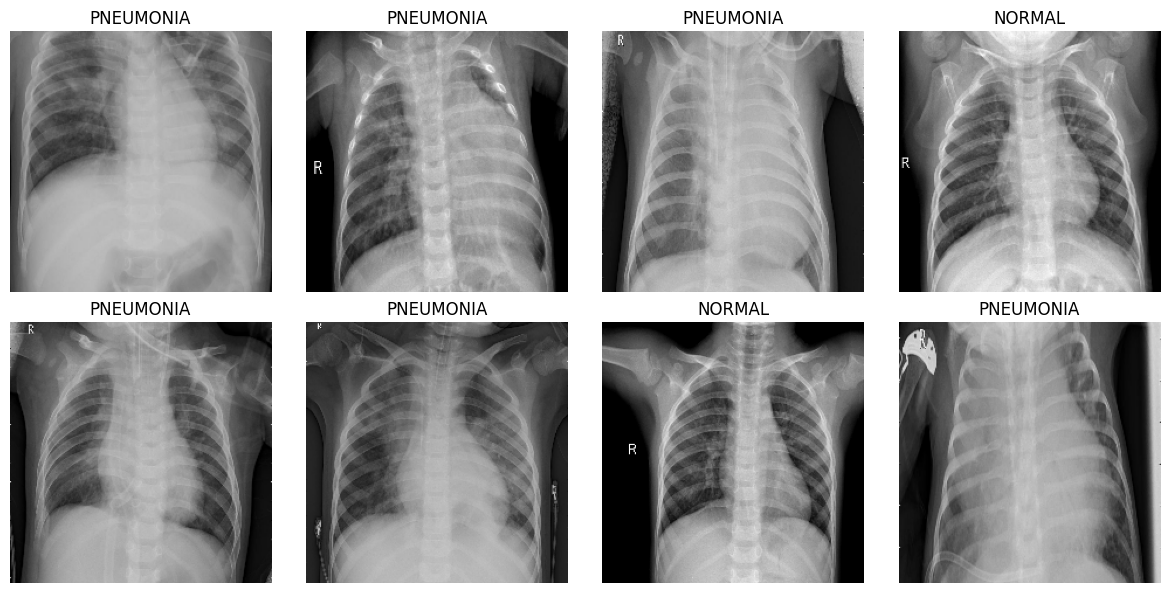

Training images per class: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [ ]:
plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout(); plt.show()

counts = {c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in class_names}
print("Training images per class:", counts)

# Class weights to handle imbalance (PNEUMONIA >> NORMAL)
total = sum(counts.values())
class_weight = {i: total / (2 * counts[c]) for i, c in enumerate(class_names)}
print("Class weights:", class_weight)

## 5. Data augmentation

In [ ]:
# No horizontal flip: anatomy (heart position) matters in chest X-rays
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.1),
], name="augmentation")

## 6. Helper functions (metrics, callbacks, plots, evaluation)

In [ ]:
METRICS = [
    "accuracy",
    keras.metrics.AUC(name="auc"),
    keras.metrics.Precision(name="precision"),
    keras.metrics.Recall(name="recall"),
]

def get_callbacks(path):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(path, monitor="val_loss",
                                        save_best_only=True),
    ]

def plot_history(histories, title):
    # histories: list of History objects (concatenated, e.g. head + fine-tune)
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in histories:
        acc += h.history["accuracy"];  val_acc += h.history["val_accuracy"]
        loss += h.history["loss"];     val_loss += h.history["val_loss"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="val")
    ax[0].set_title(f"{title} - Accuracy"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="val")
    ax[1].set_title(f"{title} - Loss"); ax[1].legend()
    plt.show()

def evaluate_model(model, name):
    y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    print(f"===== {name} : TEST RESULTS =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    auc = roc_auc_score(y_true, y_prob)
    print("ROC-AUC:", round(auc, 4))

    cm = confusion_matrix(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
                xticklabels=class_names, yticklabels=class_names)
    ax[0].set_title(f"{name} - Confusion Matrix")
    ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
    ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set_title(f"{name} - ROC Curve")
    ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
    ax[1].legend()
    plt.show()
    return {"accuracy": (y_pred == y_true).mean(), "auc": auc}

## 7. Model A: Normal CNN (built from scratch)

In [ ]:
def build_cnn():
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="custom_cnn")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy", metrics=METRICS)
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 244ms/step - accuracy: 0.8423 - auc: 0.9214 - loss: 0.3543 - precision: 0.9587 - recall: 0.8218 - val_accuracy: 0.7613 - val_auc: 0.5000 - val_loss: 3.8468 - val_precision: 0.7613 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 38s 292ms/step - accuracy: 0.8835 - auc: 0.9511 - loss: 0.2731 - precision: 0.9734 - recall: 0.8660 - val_accuracy: 0.7613 - val_auc: 0.5000 - val_loss: 2.8568 - val_precision: 0.7613 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 304ms/step - accuracy: 0.8946 - auc: 0.9589 - loss: 0.2515 - precision: 0.9718 - recall: 0.8828 - val_accuracy: 0.7613 - val_auc: 0.5000 - val_loss: 3.0867 - val_precision: 0.7613 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.9131 - auc: 0.9703 - loss: 0.2187 - precision: 0.9798 - recall: 0.8995
Epoch 4: ReduceLROnPlateau reducing learning rate to 0

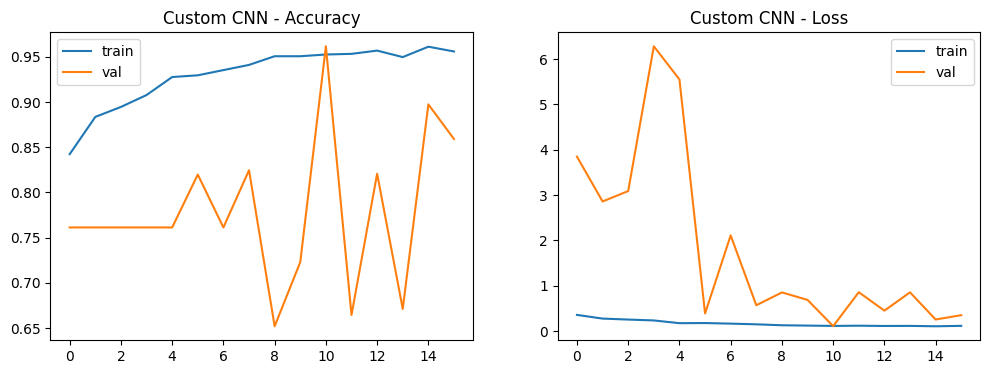

===== Custom CNN : TEST RESULTS =====
              precision    recall  f1-score   support

      NORMAL     0.9430    0.6368    0.7602       234
   PNEUMONIA     0.8176    0.9769    0.8902       390

    accuracy                         0.8494       624
   macro avg     0.8803    0.8068    0.8252       624
weighted avg     0.8646    0.8494    0.8414       624

ROC-AUC: 0.9481


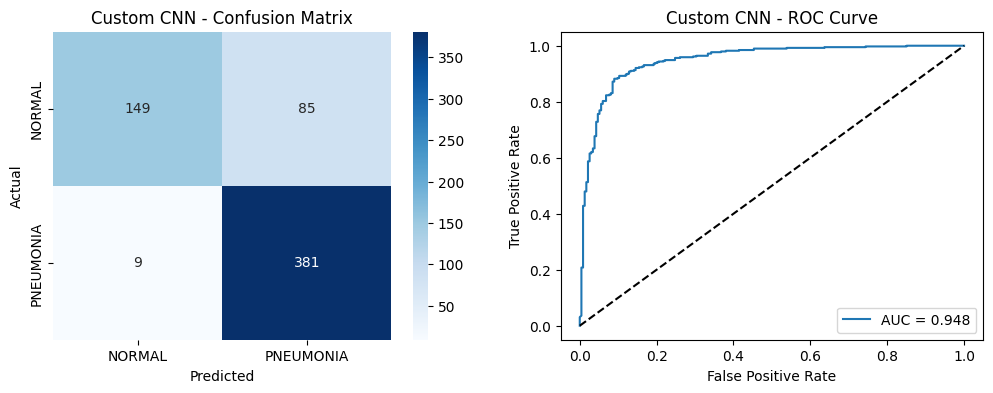

In [ ]:
hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=25,
                   class_weight=class_weight,
                   callbacks=get_callbacks("best_cnn.keras"))
plot_history([hist_cnn], "Custom CNN")
cnn_res = evaluate_model(cnn, "Custom CNN")

## 8. Model B: Transfer Learning (MobileNetV2, ImageNet weights)
**Stage 1:** train only the new classifier head (base frozen).
**Stage 2:** fine-tune the top layers of the base with a very low learning rate.

In [ ]:
def build_transfer():
    base = keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = augment(inputs)
    x = keras.applications.mobilenet_v2.preprocess_input(x)  # scales to [-1, 1]
    x = base(x, training=False)           # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="mobilenetv2_tl"), base

tl_model, base_model = build_transfer()
tl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="binary_crossentropy", metrics=METRICS)

# Stage 1: train head
hist_tl1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=10,
                        class_weight=class_weight,
                        callbacks=get_callbacks("best_tl_stage1.keras"))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 39s 251ms/step - accuracy: 0.8054 - auc: 0.9106 - loss: 0.4150 - precision: 0.9410 - recall: 0.8028 - val_accuracy: 0.9338 - val_auc: 0.9718 - val_loss: 0.2051 - val_precision: 0.9373 - val_recall: 0.9786 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 250ms/step - accuracy: 0.9027 - auc: 0.9688 - loss: 0.2402 - precision: 0.9681 - recall: 0.8978 - val_accuracy: 0.9377 - val_auc: 0.9776 - val_loss: 0.1741 - val_precision: 0.9397 - val_recall: 0.9811 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 272ms/step - accuracy: 0.9133 - auc: 0.9762 - loss: 0.2054 - precision: 0.9735 - recall: 0.9072 - val_accuracy: 0.9492 - val_auc: 0.9797 - val_loss: 0.1543 - val_precision: 0.9535 - val_recall: 0.9811 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 274ms/step - accuracy: 0.9288 - auc: 0.9816 - loss: 0.1807 - precision: 0.9784 - recall: 0.9241 - va

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 257ms/step - accuracy: 0.9492 - auc: 0.9888 - loss: 0.1224 - precision: 0.9811 - recall: 0.9535 - val_accuracy: 0.9453 - val_auc: 0.9883 - val_loss: 0.1371 - val_precision: 0.9881 - val_recall: 0.9395 - learning_rate: 1.0000e-05
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 38s 238ms/step - accuracy: 0.9530 - auc: 0.9907 - loss: 0.1184 - precision: 0.9868 - recall: 0.9490 - val_accuracy: 0.9684 - val_auc: 0.9893 - val_loss: 0.1000 - val_precision: 0.9860 - val_recall: 0.9723 - learning_rate: 1.0000e-05
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 32s 246ms/step - accuracy: 0.9614 - auc: 0.9934 - loss: 0.1011 - precision: 0.9860 - recall: 0.9614 - val_accuracy: 0.9674 - val_auc: 0.9936 - val_loss: 0.0998 - val_precision: 0.9910 - val_recall: 0.9660 - learning_rate: 1.0000e-05
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 248ms/step - accuracy: 0.9641 - auc: 0.9952 - loss: 0.0854 - precision: 0.9906 - recall: 0.9604 - val_accuracy: 0.9693 - val_auc: 0.9929 

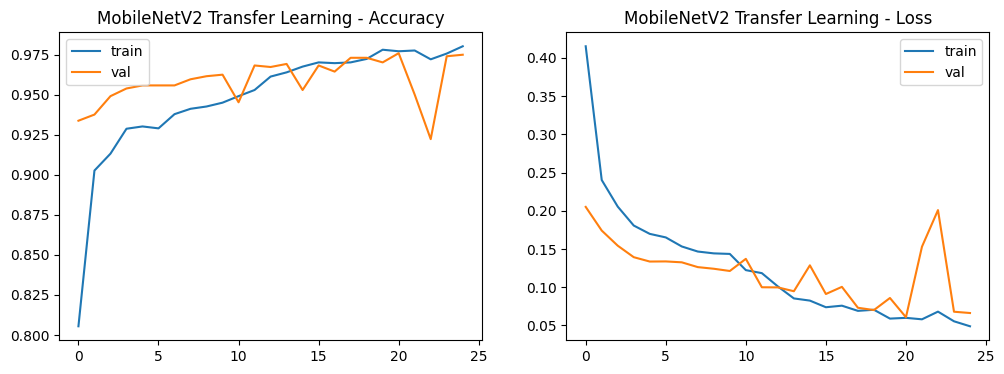

===== MobileNetV2 Transfer Learning : TEST RESULTS =====
              precision    recall  f1-score   support

      NORMAL     0.9800    0.6282    0.7656       234
   PNEUMONIA     0.8165    0.9923    0.8958       390

    accuracy                         0.8558       624
   macro avg     0.8982    0.8103    0.8307       624
weighted avg     0.8778    0.8558    0.8470       624

ROC-AUC: 0.9695


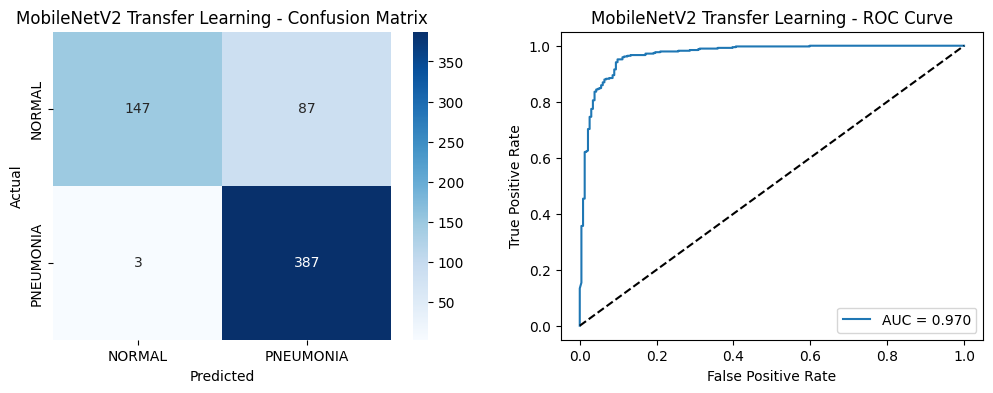

In [ ]:
# Stage 2: fine-tune last 40 layers of the base model
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False   # keep BN stats frozen for stable fine-tuning

tl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss="binary_crossentropy", metrics=METRICS)

hist_tl2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=15,
                        class_weight=class_weight,
                        callbacks=get_callbacks("best_tl_finetuned.keras"))

plot_history([hist_tl1, hist_tl2], "MobileNetV2 Transfer Learning")
tl_res = evaluate_model(tl_model, "MobileNetV2 Transfer Learning")

## 9. Compare models

In [ ]:
print(f"{'Model':35s} {'Test Acc':>10s} {'ROC-AUC':>10s}")
print(f"{'Custom CNN':35s} {cnn_res['accuracy']:10.4f} {cnn_res['auc']:10.4f}")
print(f"{'MobileNetV2 Transfer Learning':35s} {tl_res['accuracy']:10.4f} {tl_res['auc']:10.4f}")

Model                                 Test Acc    ROC-AUC
Custom CNN                              0.8494     0.9481
MobileNetV2 Transfer Learning           0.8558     0.9695


## 10. Save the best model & predict on your own X-ray

In [ ]:
tl_model.save("pneumonia_mobilenetv2.keras")

from google.colab import files
from tensorflow.keras.preprocessing import image

def predict_xray(model):
    uploaded = files.upload()
    for fname in uploaded:
        img = image.load_img(fname, target_size=IMG_SIZE)  # loads as RGB
        arr = np.expand_dims(image.img_to_array(img), 0)
        prob = float(model.predict(arr, verbose=0)[0][0])
        label = class_names[int(prob >= 0.5)]
        conf = prob if prob >= 0.5 else 1 - prob
        plt.imshow(img); plt.axis("off")
        plt.title(f"{label} ({conf*100:.1f}% confidence)")
        plt.show()

# predict_xray(tl_model)   # uncomment and run to test your own image

> ⚠️ **Disclaimer:** This is an educational project and not a medical diagnostic tool.